# 1. Tutorial 1

**Course:** High Switching Frequency Power Converters

## 1.1 Passive components of a buck converter versus switching frequency

Sweep the switching frequency of the buck converter from Task 1.1 of the exercise sheet.
Following parameters are given:
- $V_\mathrm{in} = 24~\mathrm{V}$
- $V_\mathrm{o} = 5~\mathrm{V}$
- $I_\mathrm{o} = 6~\mathrm{A}$
- $\Delta I_L = 0.4\,I_\mathrm{o}$ (peak-to-peak)
- $\Delta V_\mathrm{o} = 25~\mathrm{mV}$ (peak-to-peak)

The switching frequency shall be swept logarithmically in the range [$100~\mathrm{kHz} \ldots 30~\mathrm{MHz}$] with 200 points.

1.1.1 Import necessary modules (numpy as np and matplotlib.pyplot as plt) and add constant variables for the constant values.

1.1.2 Create the functions `get_L(f_sw)` and `get_C(f_sw)` which return the inductance and the capacitance according to
$$L = \frac{V_\mathrm{o}(1-D)}{f_\mathrm{sw}\,\Delta I_L}, \qquad C = \frac{\Delta I_L}{8 f_\mathrm{sw}\,\Delta V_\mathrm{o}}.$$

1.1.3 Create the function `get_E_L(f_sw)` which returns the peak energy stored in the inductor, $E_L = \frac{1}{2}L\hat{i}_L^2$ with $\hat{i}_L = I_\mathrm{o}+\Delta I_L/2$, and the function `get_W(f_sw)` which returns the energy $W = P_\mathrm{o}/f_\mathrm{sw}$ delivered to the load per period.

1.1.4 Plot $L$ and $C$ versus $f_\mathrm{sw}$ in a log-log diagram.

1.1.5 Plot $E_L$ and $W$ versus $f_\mathrm{sw}$ in a log-log diagram and print the ratio $E_L/W$. What do you observe?


In [1]:
# Subtask 1.1.1 Import necessary modules (numpy as np and matplotlib.pyplot as plt) and add constant variables for the constant values.

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# Fixed constants for the tutorial
# ---------------------------------------------------------------------
V_in = 24           # Unit V
V_o = 5             # Unit V
I_o = 6             # Unit A
dI_L = 0.4 * I_o    # Unit A, peak-to-peak inductor current ripple
dV_o = 25e-3        # Unit V, peak-to-peak output voltage ripple

D = V_o / V_in      # duty cycle in continuous conduction mode
P_o = V_o * I_o     # Unit W

# Logarithmic frequency sweep from 100 kHz to 30 MHz with 200 points
f_sw_range = np.logspace(np.log10(100e3), np.log10(30e6), 200)   # Unit Hz


# Subtask 1.1.2 Create the functions get_L(f_sw) and get_C(f_sw)
def get_L(f_sw):
    """Inductance in H for the given current ripple."""
    return V_o * (1 - D) / (f_sw * dI_L)


def get_C(f_sw):
    """Capacitance in F for the given voltage ripple."""
    return dI_L / (8 * f_sw * dV_o)


# Subtask 1.1.3 Create the functions get_E_L(f_sw) and get_W(f_sw)
def get_E_L(f_sw):
    """Peak energy stored in the inductor in J."""
    i_L_peak = I_o + dI_L / 2
    return 0.5 * get_L(f_sw) * i_L_peak**2


def get_W(f_sw):
    """Energy delivered to the load per switching period in J."""
    return P_o / f_sw


print(f"D = {D:.3f}, P_o = {P_o:.0f} W")
for f in [200e3, 2e6, 20e6]:
    print(f"f_sw = {f/1e6:6.2f} MHz: L = {get_L(f)*1e9:8.1f} nH, C = {get_C(f)*1e6:6.2f} uF, "
          f"E_L = {get_E_L(f)*1e6:7.2f} uJ, W = {get_W(f)*1e6:7.2f} uJ")


D = 0.208, P_o = 30 W
f_sw =   0.20 MHz: L =   8246.5 nH, C =  60.00 uF, E_L =  213.75 uJ, W =  150.00 uJ
f_sw =   2.00 MHz: L =    824.7 nH, C =   6.00 uF, E_L =   21.37 uJ, W =   15.00 uJ
f_sw =  20.00 MHz: L =     82.5 nH, C =   0.60 uF, E_L =    2.14 uJ, W =    1.50 uJ


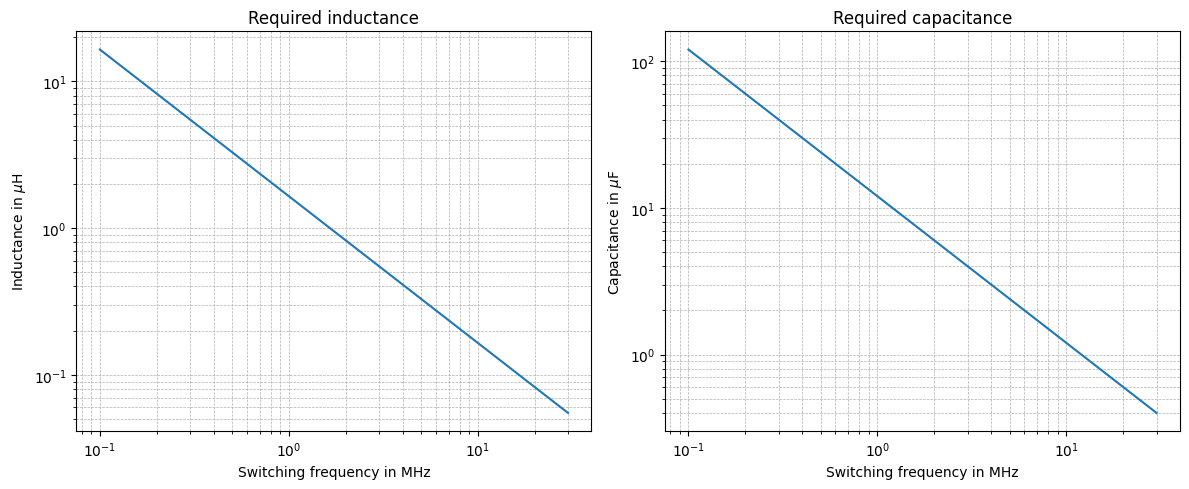

In [2]:
if __name__ == "__main__":
    # Subtask 1.1.4 Plot L and C versus f_sw
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].loglog(f_sw_range / 1e6, get_L(f_sw_range) * 1e6)
    ax[0].set_xlabel('Switching frequency in MHz')
    ax[0].set_ylabel(r'Inductance in $\mu$H')
    ax[0].set_title('Required inductance')
    ax[1].loglog(f_sw_range / 1e6, get_C(f_sw_range) * 1e6)
    ax[1].set_xlabel('Switching frequency in MHz')
    ax[1].set_ylabel(r'Capacitance in $\mu$F')
    ax[1].set_title('Required capacitance')
    for a in ax:
        a.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.tight_layout()
    plt.show()


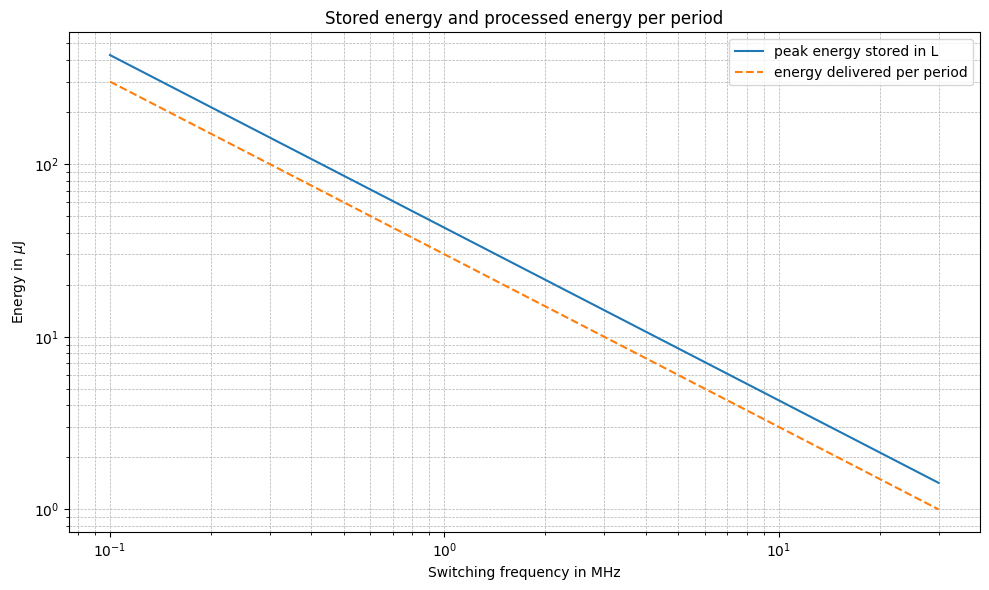

E_L / W = 1.425 ... 1.425


In [3]:
if __name__ == "__main__":
    # Subtask 1.1.5 Plot E_L and W versus f_sw and print the ratio
    plt.figure(figsize=(10, 6))
    plt.loglog(f_sw_range / 1e6, get_E_L(f_sw_range) * 1e6, label='peak energy stored in L')
    plt.loglog(f_sw_range / 1e6, get_W(f_sw_range) * 1e6, '--', label='energy delivered per period')
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel(r'Energy in $\mu$J')
    plt.title('Stored energy and processed energy per period')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    ratio = get_E_L(f_sw_range) / get_W(f_sw_range)
    print(f"E_L / W = {ratio.min():.3f} ... {ratio.max():.3f}")


### 1.1.5 Solution What do you observe?

$L$, $C$ and $E_L$ all fall with $1/f_\mathrm{sw}$. The ratio
$$\frac{E_L}{W} = \frac{(1-D)\,\hat{i}_L^2}{2\,\Delta I_L\,I_\mathrm{o}} = 1.43$$
does not depend on $f_\mathrm{sw}$: the inductor always stores about 1.4 times the energy processed in one period. Whether the component also becomes smaller depends on the flux density and current density that core and winding losses allow at the higher frequency (Lecture 1, magnetics).


## 1.2 Corner frequency and size of the EMI filter

A second-order LC filter shall attenuate the fundamental switching component by $A$. Its attenuation rises with $40~\mathrm{dB}$ per decade above the corner frequency $f_\mathrm{c}$.
Use $A \in \left\{40~\mathrm{dB}, 60~\mathrm{dB}, 80~\mathrm{dB}\right\}$ and the frequency range of 1.1.

1.2.1 Create the function `get_f_c(f_sw, A)` which returns the corner frequency $f_\mathrm{c} = f_\mathrm{sw}/10^{A/40}$ and the function `get_LC(f_c)` which returns $LC = 1/(2\pi f_\mathrm{c})^2$.

1.2.2 Plot $LC$ versus $f_\mathrm{sw}$ for the three values of $A$ in a log-log diagram. Mark the conducted-emission band from $150~\mathrm{kHz}$ to $30~\mathrm{MHz}$.

1.2.3 By which factor does $LC$ shrink when $f_\mathrm{sw}$ rises by a factor of ten? Check the result with the plot.


In [4]:
# Subtask 1.2.1 Create the functions get_f_c(f_sw, A) and get_LC(f_c)
A_list = [40, 60, 80]   # Unit dB


def get_f_c(f_sw, A):
    """Corner frequency in Hz of a second-order filter with A dB attenuation at f_sw."""
    return f_sw / 10**(A / 40)


def get_LC(f_c):
    """LC product in s^2 for the corner frequency f_c."""
    return 1 / (2 * np.pi * f_c)**2


for f in [200e3, 2e6]:
    f_c = get_f_c(f, 60)
    print(f"f_sw = {f/1e3:6.0f} kHz, A = 60 dB: f_c = {f_c/1e3:6.2f} kHz, LC = {get_LC(f_c):.3e} s^2")


f_sw =    200 kHz, A = 60 dB: f_c =   6.32 kHz, LC = 6.333e-10 s^2
f_sw =   2000 kHz, A = 60 dB: f_c =  63.25 kHz, LC = 6.333e-12 s^2


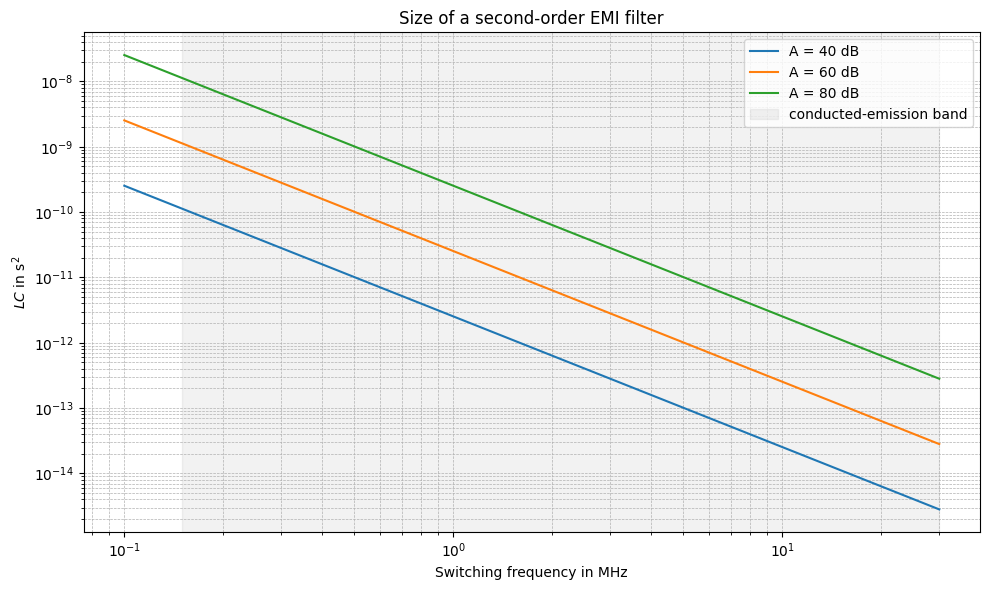

LC(200 kHz) / LC(2 MHz) = 100


In [5]:
if __name__ == "__main__":
    # Subtask 1.2.2 Plot LC versus f_sw for the three attenuations
    plt.figure(figsize=(10, 6))
    for A in A_list:
        plt.loglog(f_sw_range / 1e6, get_LC(get_f_c(f_sw_range, A)), label=f'A = {A} dB')
    plt.axvspan(0.15, 30, alpha=0.1, color='gray', label='conducted-emission band')
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel(r'$LC$ in s$^2$')
    plt.title('Size of a second-order EMI filter')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Subtask 1.2.3 Factor for ten times the switching frequency
    factor = get_LC(get_f_c(200e3, 60)) / get_LC(get_f_c(2e6, 60))
    print(f"LC(200 kHz) / LC(2 MHz) = {factor:.0f}")


### 1.2.3 Solution By which factor does $LC$ shrink?

$f_\mathrm{c}$ is proportional to $f_\mathrm{sw}$ and $LC \propto 1/f_\mathrm{c}^2$, so ten times $f_\mathrm{sw}$ gives a 100 times smaller $LC$. In the log-log plot all lines have the slope $-2$. In practice the self-resonance of the filter components limits this gain (exercise sheet, Task 1.2.3).


## 1.3 Skin depth and optimum foil thickness

Following parameters are given:
- $\rho_{20} = 1.72\cdot 10^{-8}~\mathrm{\Omega m}$ (copper at $20~^\circ\mathrm{C}$)
- $\alpha_\mathrm{Cu} = 3.93\cdot 10^{-3}~\mathrm{K^{-1}}$
- $\mu_0 = 4\pi\cdot 10^{-7}~\mathrm{H/m}$

1.3.1 Create the function `get_rho(T)` which returns the resistivity at the temperature $T$ in $^\circ\mathrm{C}$ and the function `get_delta(f, T)` which returns the skin depth
$$\delta = \sqrt{\frac{\rho(T)}{\pi f \mu_0}}.$$

1.3.2 Plot $\delta$ versus $f$ in the range [$100~\mathrm{kHz} \ldots 30~\mathrm{MHz}$] for $20~^\circ\mathrm{C}$ and $100~^\circ\mathrm{C}$ in a log-log diagram. Add horizontal lines for 1 oz copper ($35~\mathrm{\mu m}$), 2 oz copper ($70~\mathrm{\mu m}$) and the diameter of a 50 AWG litz strand ($25.4~\mathrm{\mu m}$). At which frequencies does $\delta$ equal these thicknesses?

1.3.3 A single-layer foil winding with the magnetic field on one side has the AC resistance per unit width and length
$$R'_\mathrm{ac} = \frac{\rho}{\delta}\,g(\Delta), \qquad g(\Delta) = \frac{\sinh 2\Delta + \sin 2\Delta}{\cosh 2\Delta - \cos 2\Delta}, \qquad \Delta = \frac{h}{\delta}.$$
Create the function `get_R_ac_foil(h, f, T)` and plot $R'_\mathrm{ac}$ versus the foil thickness $h$ in the range [$5 \ldots 150~\mathrm{\mu m}$] for $f = 1~\mathrm{MHz}$, $6.78~\mathrm{MHz}$ and $13.56~\mathrm{MHz}$ at $20~^\circ\mathrm{C}$. Add the DC resistance $\rho/h$ for comparison.

1.3.4 Find the optimum thickness numerically (e.g. with `scipy.optimize.minimize_scalar`) for the three frequencies and compare it with $\frac{\pi}{2}\delta$.


In [6]:
# Subtask 1.3.1 Create the functions get_rho(T) and get_delta(f, T)
from scipy.optimize import minimize_scalar

rho_20 = 1.72e-8          # Unit Ohm m
alpha_Cu = 3.93e-3        # Unit 1/K
mu_0 = 4 * np.pi * 1e-7   # Unit H/m


def get_rho(T):
    """Resistivity of copper in Ohm m at the temperature T in degC."""
    return rho_20 * (1 + alpha_Cu * (T - 20))


def get_delta(f, T=20):
    """Skin depth of copper in m."""
    return np.sqrt(get_rho(T) / (np.pi * f * mu_0))


for f in [100e3, 1e6, 6.78e6, 13.56e6, 30e6]:
    print(f"f = {f/1e6:6.2f} MHz: delta = {get_delta(f, 20)*1e6:6.1f} um (20 degC), "
          f"{get_delta(f, 100)*1e6:6.1f} um (100 degC)")


f =   0.10 MHz: delta =  208.7 um (20 degC),  239.3 um (100 degC)
f =   1.00 MHz: delta =   66.0 um (20 degC),   75.7 um (100 degC)
f =   6.78 MHz: delta =   25.3 um (20 degC),   29.1 um (100 degC)
f =  13.56 MHz: delta =   17.9 um (20 degC),   20.6 um (100 degC)
f =  30.00 MHz: delta =   12.1 um (20 degC),   13.8 um (100 degC)


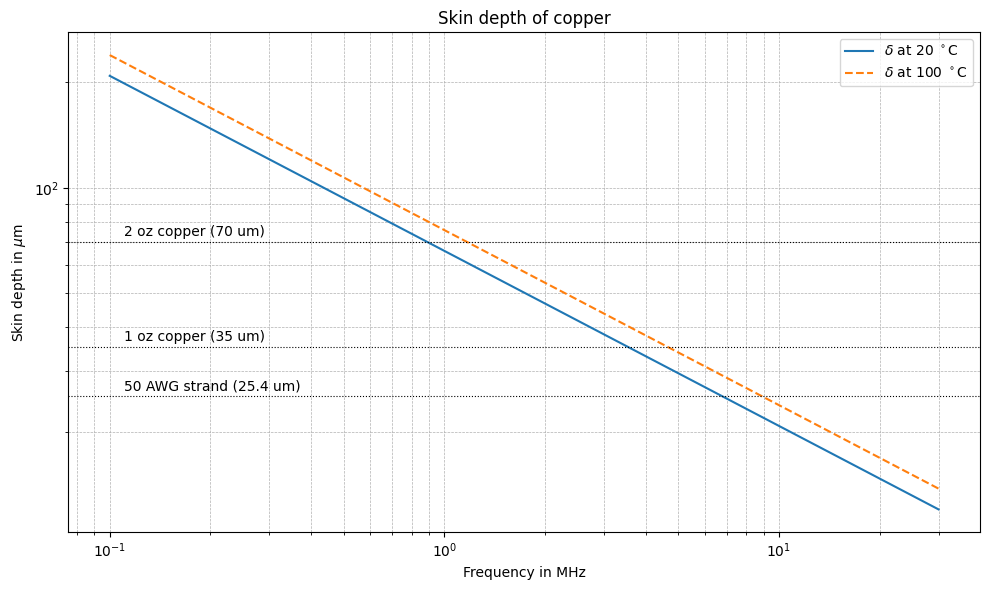

delta = 1 oz copper (35 um): f = 3.56 MHz (20 degC)
delta = 2 oz copper (70 um): f = 0.89 MHz (20 degC)
delta = 50 AWG strand (25.4 um): f = 6.75 MHz (20 degC)


In [7]:
if __name__ == "__main__":
    # Subtask 1.3.2 Plot delta versus f and compare with copper and litz-strand thicknesses
    f_range = np.logspace(np.log10(100e3), np.log10(30e6), 200)
    thicknesses = {'1 oz copper (35 um)': 35e-6, '2 oz copper (70 um)': 70e-6, '50 AWG strand (25.4 um)': 25.4e-6}

    plt.figure(figsize=(10, 6))
    plt.loglog(f_range / 1e6, get_delta(f_range, 20) * 1e6, label=r'$\delta$ at 20 $^\circ$C')
    plt.loglog(f_range / 1e6, get_delta(f_range, 100) * 1e6, '--', label=r'$\delta$ at 100 $^\circ$C')
    for name, h in thicknesses.items():
        plt.axhline(h * 1e6, linestyle=':', color='black', linewidth=0.8)
        plt.text(0.11, h * 1e6 * 1.04, name)
    plt.xlabel('Frequency in MHz')
    plt.ylabel(r'Skin depth in $\mu$m')
    plt.title('Skin depth of copper')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Frequency at which delta equals the thickness h: f = rho / (pi mu_0 h^2)
    for name, h in thicknesses.items():
        f_eq = get_rho(20) / (np.pi * mu_0 * h**2)
        print(f"delta = {name}: f = {f_eq/1e6:.2f} MHz (20 degC)")


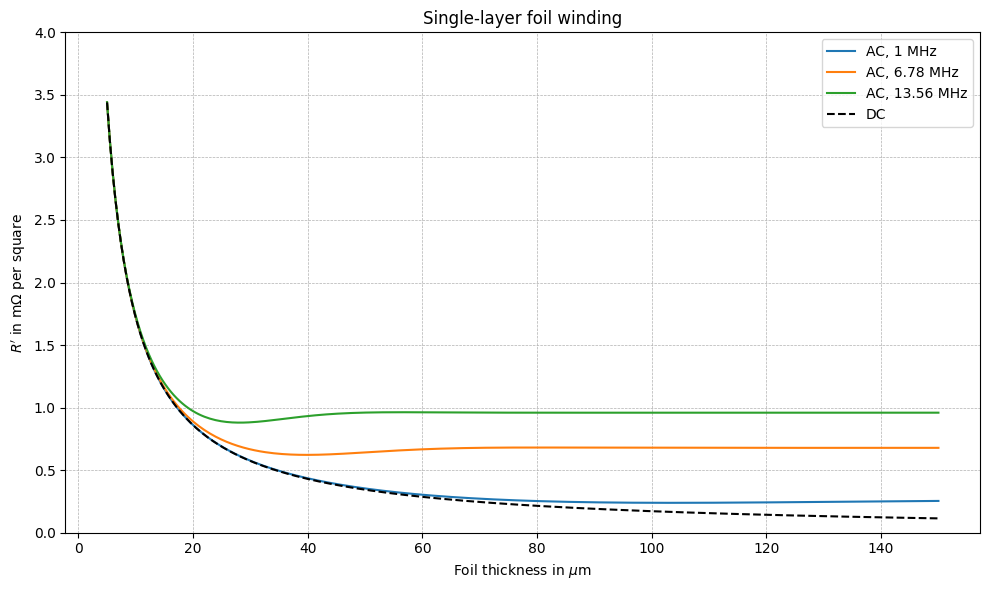

In [8]:
# Subtask 1.3.3 AC resistance of a single-layer foil winding
def g(Delta):
    """Normalised AC resistance of a single layer with the field on one side."""
    return (np.sinh(2 * Delta) + np.sin(2 * Delta)) / (np.cosh(2 * Delta) - np.cos(2 * Delta))


def get_R_ac_foil(h, f, T=20):
    """AC resistance per unit width and length in Ohm (per square) of a foil with thickness h."""
    delta = get_delta(f, T)
    return get_rho(T) / delta * g(h / delta)


if __name__ == "__main__":
    h_range = np.linspace(5e-6, 150e-6, 300)
    plt.figure(figsize=(10, 6))
    for f in [1e6, 6.78e6, 13.56e6]:
        plt.plot(h_range * 1e6, get_R_ac_foil(h_range, f) * 1e3, label=f'AC, {f/1e6:g} MHz')
    plt.plot(h_range * 1e6, get_rho(20) / h_range * 1e3, 'k--', label='DC')
    plt.ylim(0, 4)
    plt.xlabel(r'Foil thickness in $\mu$m')
    plt.ylabel(r"$R'$ in m$\Omega$ per square")
    plt.title('Single-layer foil winding')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [9]:
# Subtask 1.3.4 Optimum thickness found numerically and compared with pi/2 * delta
# g(Delta) has further, very shallow minima at Delta = 3*pi/2, 5*pi/2, ... (g is then almost 1).
# The search is therefore bracketed around the first minimum: 0.5*delta ... 2.5*delta.
for f in [1e6, 6.78e6, 13.56e6]:
    delta = get_delta(f)
    res = minimize_scalar(lambda h: get_R_ac_foil(h, f), bounds=(0.5 * delta, 2.5 * delta), method='bounded',
                          options={'xatol': 1e-10})
    print(f"f = {f/1e6:6.2f} MHz: h_opt = {res.x*1e6:5.1f} um, pi/2*delta = {np.pi/2*delta*1e6:5.1f} um, "
          f"g(h_opt/delta) = {g(res.x/delta):.4f}")

f = 6.78e6
ratio = get_R_ac_foil(70e-6, f) / get_R_ac_foil(35e-6, f)
print(f"6.78 MHz: R_ac(2 oz) / R_ac(1 oz) = {ratio:.3f}")


f =   1.00 MHz: h_opt = 103.7 um, pi/2*delta = 103.7 um, g(h_opt/delta) = 0.9172
f =   6.78 MHz: h_opt =  39.8 um, pi/2*delta =  39.8 um, g(h_opt/delta) = 0.9172
f =  13.56 MHz: h_opt =  28.2 um, pi/2*delta =  28.2 um, g(h_opt/delta) = 0.9172
6.78 MHz: R_ac(2 oz) / R_ac(1 oz) = 1.076


### 1.3.4 Solution Optimum foil thickness

The numerical optimum equals $\frac{\pi}{2}\delta$ at every frequency, with $g = 0.917$ (exercise sheet, Task 1.3.3, for the analytical proof). Copper beyond this thickness does not reduce the AC resistance: for $h \gg \delta$ the resistance approaches $\rho/\delta$, independent of $h$. At $6.78~\mathrm{MHz}$ the 2 oz foil has about $7.5~\%$ more AC resistance than the 1 oz foil.


## 1.4 Capacitive switching loss and the limit of hard switching

Use the three applications of Task 1.4 of the exercise sheet:
- A: $V_\mathrm{DC} = 400~\mathrm{V}$, $Q_\mathrm{oss} = 56~\mathrm{nC}$, $P_\mathrm{o} = 1.5~\mathrm{kW}$
- B: $V_\mathrm{DC} = 48~\mathrm{V}$, $Q_\mathrm{oss} = 25~\mathrm{nC}$, $P_\mathrm{o} = 500~\mathrm{W}$
- C: $V_\mathrm{DC} = 12~\mathrm{V}$, $Q_\mathrm{oss} = 5~\mathrm{nC}$, $P_\mathrm{o} = 50~\mathrm{W}$

1.4.1 Create a dictionary `Apps` with the keys 'A', 'B' and 'C'. Assign to each key an inner dictionary with the keys 'V_DC', 'Q_oss' and 'P_o'. E.g. access to a value is `Apps["A"]["V_DC"]`.

1.4.2 Create the function `get_P_Qoss(f_sw, V_DC, Q_oss)` which returns the capacitive switching loss $P = Q_\mathrm{oss}V_\mathrm{DC}f_\mathrm{sw}$ of a hard-switched half-bridge.

1.4.3 Plot $P/P_\mathrm{o}$ in percent versus $f_\mathrm{sw}$ in the range [$10~\mathrm{kHz} \ldots 30~\mathrm{MHz}$] for the three applications in a log-log diagram and add a horizontal line at $1~\%$. Print the frequency $f_{1\%}$ at which each application reaches $1~\%$.

1.4.4 Which of the applications can be hard-switched at $2~\mathrm{MHz}$ with less than $1~\%$ capacitive switching loss? Which additional loss mechanisms are not included in this model?


In [10]:
# Subtask 1.4.1 Create a dictionary with the three applications
Apps = {
    'A': {'V_DC': 400, 'Q_oss': 56e-9, 'P_o': 1500},
    'B': {'V_DC': 48, 'Q_oss': 25e-9, 'P_o': 500},
    'C': {'V_DC': 12, 'Q_oss': 5e-9, 'P_o': 50},
}


# Subtask 1.4.2 Create the function get_P_Qoss(f_sw, V_DC, Q_oss)
def get_P_Qoss(f_sw, V_DC, Q_oss):
    """Capacitive switching loss in W of a hard-switched half-bridge (identical switches)."""
    return Q_oss * V_DC * f_sw


Application A: E = 22.40 uJ, f_1% = 0.67 MHz
Application B: E = 1.20 uJ, f_1% = 4.17 MHz
Application C: E = 0.06 uJ, f_1% = 8.33 MHz


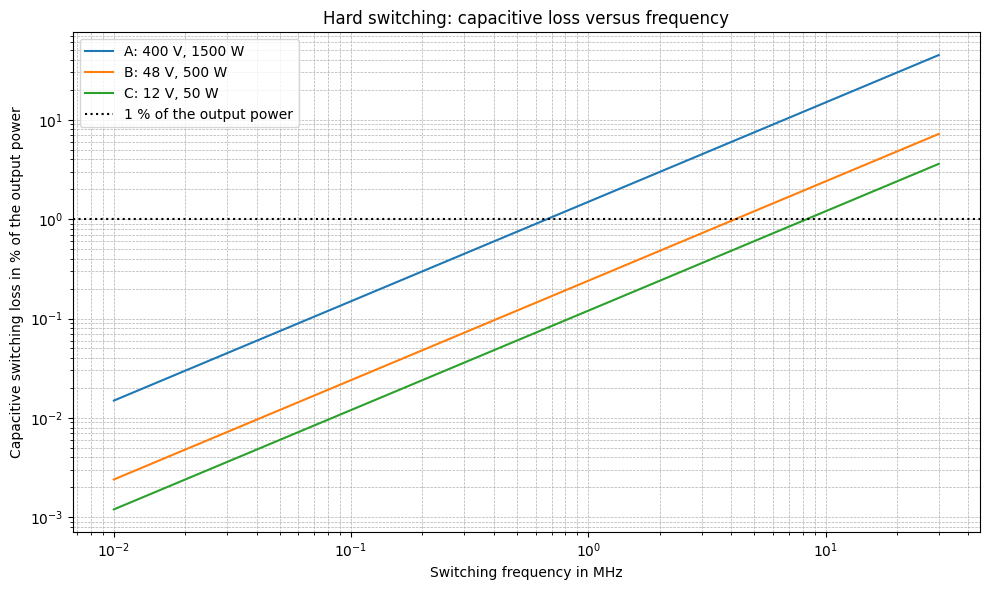

In [11]:
if __name__ == "__main__":
    # Subtask 1.4.3 Plot P/P_o versus f_sw and print the 1 % frequency
    f_range = np.logspace(np.log10(10e3), np.log10(30e6), 200)
    plt.figure(figsize=(10, 6))
    for name, app in Apps.items():
        rel = get_P_Qoss(f_range, app['V_DC'], app['Q_oss']) / app['P_o'] * 100
        plt.loglog(f_range / 1e6, rel, label=f"{name}: {app['V_DC']} V, {app['P_o']} W")
        f_1 = 0.01 * app['P_o'] / (app['Q_oss'] * app['V_DC'])
        print(f"Application {name}: E = {app['Q_oss']*app['V_DC']*1e6:.2f} uJ, f_1% = {f_1/1e6:.2f} MHz")
    plt.axhline(1, color='black', linestyle=':', label='1 % of the output power')
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel('Capacitive switching loss in % of the output power')
    plt.title('Hard switching: capacitive loss versus frequency')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 1.4.4 Solution Which application can be hard-switched at 2 MHz?

Only B ($f_{1\%} = 4.2~\mathrm{MHz}$) and C ($f_{1\%} = 8.3~\mathrm{MHz}$). Application A reaches $1~\%$ already at $670~\mathrm{kHz}$ and needs zero-voltage switching above that.

The model contains only $Q_\mathrm{oss}V_\mathrm{DC}$. It does not include the $V$--$I$ overlap loss, which dominates at low voltage and high current, reverse recovery, gate-drive loss, dead-time conduction and $C_\mathrm{oss}$ hysteresis. Tutorial 2 builds the complete loss model.
